In [1]:
# RANDOM FOREST
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
from sklearn import datasets

In [4]:
iris=datasets.load_iris()

In [7]:
data=pd.DataFrame({"sepal_length":iris.data[:,0],
                   "sepal_width":iris.data[:,1],
                   "petal_length":iris.data[:,2],
                   "petal_width":iris.data[:,3],
                   "output":iris.target
                   })

In [8]:
data

,sepal_length,sepal_width,petal_length,petal_width,output
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [9]:
# SPLITTING THE DATASET IN TRAIN-TEST SUBSETS

from sklearn.model_selection import train_test_split


In [10]:
# feature and output splitting

X=data[['sepal_length', 'sepal_width','petal_length','petal_width']]
Y=data['output']



In [17]:
X_train, X_test, Y_train, Y_test= train_test_split(X,Y,test_size=0.2, random_state=42)

In [12]:
# defining model

from sklearn.ensemble import RandomForestClassifier

In [13]:
model=RandomForestClassifier(n_estimators=100)

In [14]:
model.fit(X_train,Y_train)

RandomForestClassifier()

In [18]:
from sklearn.metrics import accuracy_score
y_pred=model.predict(X_test)
print(accuracy_score(Y_test, y_pred))

1.0


In [22]:
a=np.arange(50,500,50)
accuracy_values=[]
for i in a:
  model=RandomForestClassifier(n_estimators=i)
  model.fit(X_train, Y_train)
  y_pred=model.predict(X_test)
  accuracy_values.append(accuracy_score(Y_test, y_pred))



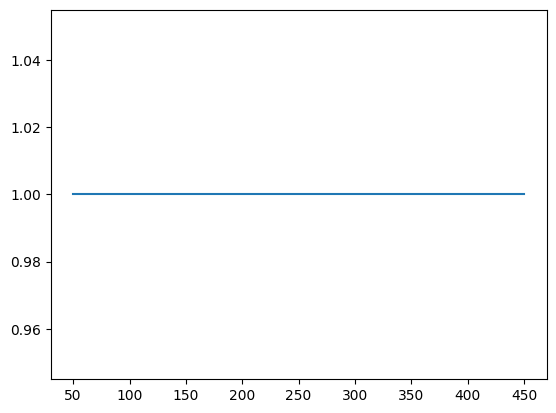

In [23]:
plt.plot(a,accuracy_values)
plt.show()

In [24]:
# VISUALIZATION OF TREES
from sklearn.tree import export_graphviz
import pydot

In [25]:
tree=model.estimators_[10]
export_graphviz(tree, out_file='tree.dot', feature_names=iris.feature_names)
(graph,)=pydot.graph_from_dot_file('tree.dot')
graph.write_png('tree.png')

# creating graph from the generated dot (decision format) file and then exporting that graph file as png